In [1]:
from sklearn.datasets import load_breast_cancer

from sklearn.naive_bayes import GaussianNB

import sklearn.metrics as metrics
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import confusion_matrix

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
X, y = load_breast_cancer(return_X_y=True)

In [3]:
nb = GaussianNB()
nb.fit(X,y)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [4]:
print(f"Score: {nb.score(X,y)}")

# 0 - maligno
# 1 - benigno
y_prob = nb.predict_proba(X)[:,1]
y_pred = nb.predict(X)
print(metrics.classification_report(y, y_pred))

Score: 0.9420035149384886
              precision    recall  f1-score   support

           0       0.95      0.89      0.92       212
           1       0.94      0.97      0.95       357

    accuracy                           0.94       569
   macro avg       0.94      0.93      0.94       569
weighted avg       0.94      0.94      0.94       569



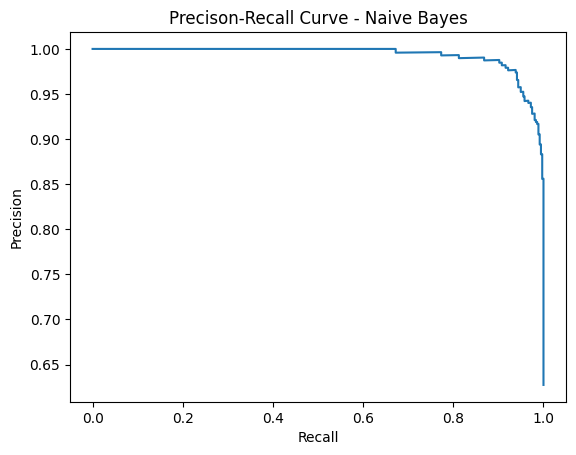


AP = 0.993


In [5]:
precision, recall, thresholds = precision_recall_curve(y, y_prob)
ap = average_precision_score(y, y_prob)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precison-Recall Curve - Naive Bayes")
plt.show()

print(f"\nAP = {ap:.3f}")

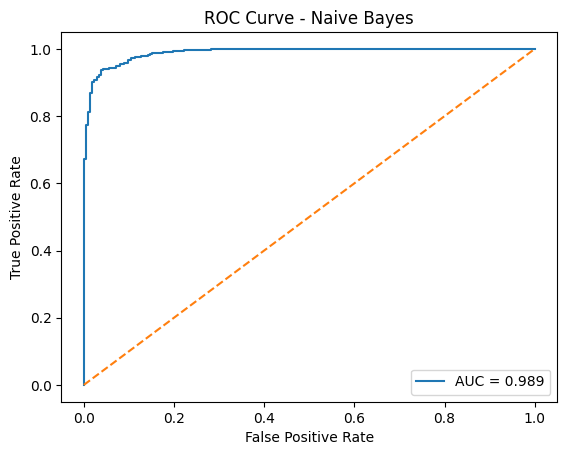


AUC: 0.9890333491887321


In [6]:
fpr, tpr, thresholds = roc_curve(y, y_prob, drop_intermediate=False)

auc = roc_auc_score(y, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")
plt.legend()
plt.show()

print("\nAUC:", auc)

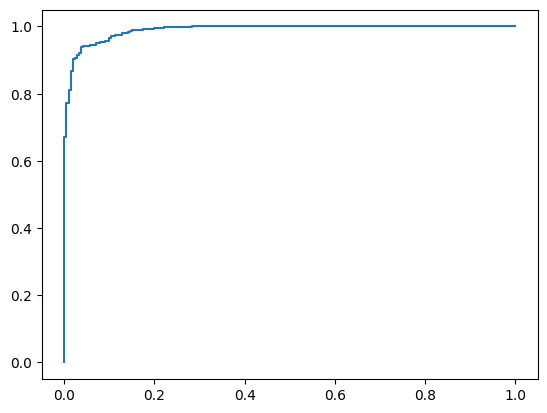

In [7]:
tpr = []
fpr = []

for t in thresholds:
    y_pred = y_prob >= t

    cm = confusion_matrix(y, y_pred)
    TN, FP, FN, TP = cm.ravel()
    TPR = TP / (TP + FN)
    FPR = FP / (FP + TN)
    tpr.append(TPR)
    fpr.append(FPR)

plt.plot(fpr, tpr)
plt.show()

In [8]:
t = 0.5
cm = confusion_matrix(y, y_prob >= t)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
)

print(f"Confusion matrix at threshold {t}")
print("-" * 50)
print(cm_df)

Confusion matrix at threshold 0.5
--------------------------------------------------
                 Predicted Negative  Predicted Positive
Actual Negative                 189                  23
Actual Positive                  10                 347


## Análise dos resultados

**Desempenho geral.** O Naive Bayes atinge acurácia de cerca de 94% e AUC de 0,989, o que indica boa capacidade de separar os dois grupos. Porém, essas métricas foram calculadas sobre os mesmos dados usados no treino (`nb.score(X, y)`), sem separação treino/teste nem validação cruzada, então tendem a ser otimistas.

**Foco na classe maligna.** A matriz de confusão mostra 23 tumores malignos classificados como benignos. Em um contexto clínico, esse é o erro mais grave. A recall da classe maligna é de aproximadamente 0,89, ou seja, cerca de 11% dos casos malignos passariam despercebidos. Já a classe benigna tem recall de 0,97, e é ela que as curvas PR e ROC medem por padrão, pois o rótulo positivo é o benigno (y = 1).

**Curvas PR e ROC.** A classe benigna é a majoritária (357 de 569, cerca de 63%). Por isso, o AP de 0,993 está inflado: um classificador aleatório teria AP em torno de 0,63 nesse cenário. Para avaliar a detecção de malignos, seria mais informativo inverter o rótulo positivo.

**Threshold.** O limiar de 0,5 foi usado por padrão, sem justificativa. Como o custo de um falso negativo é alto, vale analisar outros limiares e escolher um que priorize a recall da classe maligna, aceitando mais falsos positivos.

**Limitações do modelo.** O Naive Bayes assume independência entre as variáveis, mas atributos como raio, perímetro e área são fortemente correlacionados. Mesmo assim o modelo tem bom desempenho, porém suas probabilidades tendem a ser mal calibradas (excessivamente confiantes), o que afeta a interpretação do threshold.

**Conclusão.** O modelo é um bom ponto de partida, mas esses resultados não bastam para afirmar desempenho clínico. Os próximos passos seriam: separar treino e teste (ou usar validação cruzada estratificada), reportar métricas específicas para a classe maligna, analisar diferentes limiares e comparar com outro modelo, como a regressão logística.